# Import Libraries

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xo_env
from q_learning import QLearningAgent
from quantized_q_table import QuantizedQTable

from show_video import show_video
from video_maker import VideoMaker
import object_cache

# Env Exploration

In [45]:
env = xo_env.XO_Env()

In [46]:
s = env.reset()
s

array([2, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [47]:
env.getStateShape()

(10,)

In [48]:
env.getActionsCount()

9

In [49]:
env.getStatesMinMax()

(array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0]), array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2]))

In [50]:
env.getStatesActionsNames()

(['current_player',
  'cell_0_0',
  'cell_0_1',
  'cell_0_2',
  'cell_1_0',
  'cell_1_1',
  'cell_1_2',
  'cell_2_0',
  'cell_2_1',
  'cell_2_2'],
 ['place_in_0_0',
  'place_in_0_1',
  'place_in_0_2',
  'place_in_1_0',
  'place_in_1_1',
  'place_in_1_2',
  'place_in_2_0',
  'place_in_2_1',
  'place_in_2_2'])

# Random Walk

In [51]:
def randomWalk():
    frames = []
    s = env.reset()
    d = False

    random_policy = lambda s: np.random.randint(env.getActionsCount())
    
    while d == False:
        frames.append(env.render())
        a = np.random.randint(env.getActionsCount())
        s,d,r = env.two_steps(random_policy, random_policy)
        
    frames.append(env.render())  
    return frames

In [52]:
for i in range(3):
    video = VideoMaker(f"random_walk_{i:2d}", fps=5)
    video.extend(randomWalk())
    video.export()
    show_video(video.path())

Moviepy - Building video video\random_walk_ 0.mp4.
Moviepy - Writing video video\random_walk_ 0.mp4



Moviepy - Done !
Moviepy - video ready video\random_walk_ 0.mp4


Moviepy - Building video video\random_walk_ 1.mp4.
Moviepy - Writing video video\random_walk_ 1.mp4



Moviepy - Done !
Moviepy - video ready video\random_walk_ 1.mp4


Moviepy - Building video video\random_walk_ 2.mp4.
Moviepy - Writing video video\random_walk_ 2.mp4



Moviepy - Done !
Moviepy - video ready video\random_walk_ 2.mp4


# Build Agent & Q Table

In [53]:
n_action = env.getActionsCount()
state_lenght = env.getStateShape()[0]
state_names, action_names = env.getStatesActionsNames()
state_min, state_max = env.getStatesMinMax()

In [54]:
q_table = QuantizedQTable(
    n_actions= n_action,
    action_names= action_names,
    state_names= state_names,
    states_min_vals= state_min,
    states_max_vals= state_max,
    n_quantization_lvls= state_max - state_min + 1,
    cache_folder= 'q_table_cache',
    use_access_counter= True,
)

Cache file exists, loading from it.


In [55]:
q_learning_agent = QLearningAgent(
    env= env,
    q_table= q_table,
    alpha= 0.1,
    discount_factor= 0.95,
    max_steps_per_episode= 20,
)

# Test Env

In [56]:
history_list = object_cache.loadObject("history_list", lambda: [])

Object successfully loaded from cache\history_list.pickle


In [57]:
def try_greedy_policy(title, export=True, n_max_allowed_steps=20):
    s = env.reset()
    d = False
    total_return = 0
    
    steps_counter = 0
    
    video = VideoMaker(title, resize_shape= (700,700), fps=6)

    greedy_policy = lambda s: q_learning_agent.act(s)
        
    while not d and (steps_counter < n_max_allowed_steps):
        video.append(env.render())
        video.setText(f"{title}", color=(0,0,0),txt_position=(3,30))
        video.setText(f"Return: {total_return:+02.2f}, Steps: {steps_counter}", color=(0,0,0),txt_position=(3,60))
        
        a = q_learning_agent.act(s)
        s, d, r= env.two_steps(greedy_policy, greedy_policy)
        
        total_return += r
        
        steps_counter+=1

    for i in range(5):
        video.append(env.render())
        video.setText(f"{title}", color=(0,0,0),txt_position=(3,30))
        video.setText(f"Return: {total_return:+02.2f}, Steps: {steps_counter}", color=(0,0,0),txt_position=(3,60))
        
    if export==True:
        show_video(video.export())
        
    return total_return, video

In [58]:
try_greedy_policy("try_before_training")

Moviepy - Building video video\try_before_training.mp4.
Moviepy - Writing video video\try_before_training.mp4



Moviepy - Done !
Moviepy - video ready video\try_before_training.mp4


(-15.16, <video_maker.VideoMaker at 0x2161973bd60>)

# Train

In [59]:
n_episodes = 200_000

In [60]:
def train_agent(n_episodes):

    for episode in range(len(history_list), n_episodes):

        epsilon = max(np.log10(1 - (episode / n_episodes)) + 0.9999, 0.05)

        G, s_counter = q_learning_agent.train_episode(epsilon)

        history_list.append([G, s_counter, epsilon])

        print(f"Episode {episode + 1:04d} / {n_episodes}, Epsilion: {epsilon:+0.3f}, Return = {G:+06.2f}, Steps = {s_counter:02d}")

        if (episode+1) % 5_000 == 0:
            try_greedy_policy(f"Agent after {episode+1} episodes")


    object_cache.saveObject(history_list, "history_list")
    q_table.save_to_cache()
    q_table.export2pandas()
        

In [61]:
train_agent(n_episodes)

Episode 50001 / 200000, Epsilion: +0.875, Return = +00.92, Steps = 03
Episode 50002 / 200000, Epsilion: +0.875, Return = -15.12, Steps = 04
Episode 50003 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50004 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50005 / 200000, Epsilion: +0.875, Return = +00.92, Steps = 03
Episode 50006 / 200000, Epsilion: +0.875, Return = -15.12, Steps = 04
Episode 50007 / 200000, Epsilion: +0.875, Return = -15.12, Steps = 04
Episode 50008 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50009 / 200000, Epsilion: +0.875, Return = -15.16, Steps = 05
Episode 50010 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50011 / 200000, Epsilion: +0.875, Return = -15.12, Steps = 04
Episode 50012 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50013 / 200000, Epsilion: +0.875, Return = -15.08, Steps = 03
Episode 50014 / 200000, Epsilion: +0.875, Return = -15.04, Steps = 02
Episode 50015 / 2000

Moviepy - Done !
Moviepy - video ready video\Agent after 55000 episodes.mp4


Episode 55001 / 200000, Epsilion: +0.860, Return = -15.12, Steps = 04
Episode 55002 / 200000, Epsilion: +0.860, Return = -15.20, Steps = 06
Episode 55003 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55004 / 200000, Epsilion: +0.860, Return = -15.12, Steps = 04
Episode 55005 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55006 / 200000, Epsilion: +0.860, Return = -01.08, Steps = 03
Episode 55007 / 200000, Epsilion: +0.860, Return = -15.16, Steps = 05
Episode 55008 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55009 / 200000, Epsilion: +0.860, Return = -01.08, Steps = 03
Episode 55010 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55011 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55012 / 200000, Epsilion: +0.860, Return = -15.08, Steps = 03
Episode 55013 / 200000, Epsilion: +0.860, Return = -15.04, Steps = 02
Episode 55014 / 200000, Epsilion: +0.860, Return = -15.12, Steps = 04
Episode 55015 / 2000

Moviepy - Done !
Moviepy - video ready video\Agent after 60000 episodes.mp4


Episode 60001 / 200000, Epsilion: +0.845, Return = -15.12, Steps = 04
Episode 60002 / 200000, Epsilion: +0.845, Return = -15.12, Steps = 04
Episode 60003 / 200000, Epsilion: +0.845, Return = -15.04, Steps = 02
Episode 60004 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60005 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60006 / 200000, Epsilion: +0.845, Return = -15.16, Steps = 05
Episode 60007 / 200000, Epsilion: +0.845, Return = -15.12, Steps = 04
Episode 60008 / 200000, Epsilion: +0.845, Return = -15.16, Steps = 05
Episode 60009 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60010 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60011 / 200000, Epsilion: +0.845, Return = -15.04, Steps = 02
Episode 60012 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60013 / 200000, Epsilion: +0.845, Return = -15.08, Steps = 03
Episode 60014 / 200000, Epsilion: +0.845, Return = -15.04, Steps = 02
Episode 60015 / 2000

...

Episode 190001 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190002 / 200000, Epsilion: +0.050, Return = -15.08, Steps = 03
Episode 190003 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 190004 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190005 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190006 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190007 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 190008 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190009 / 200000, Epsilion: +0.050, Return = -15.16, Steps = 05
Episode 190010 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190011 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190012 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190013 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 190014 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episod

Moviepy - Done !
Moviepy - video ready video\Agent after 195000 episodes.mp4


Episode 195001 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195002 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195003 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195004 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195005 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195006 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195007 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 195008 / 200000, Epsilion: +0.050, Return = +00.34, Steps = 05
Episode 195009 / 200000, Epsilion: +0.050, Return = +00.34, Steps = 05
Episode 195010 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195011 / 200000, Epsilion: +0.050, Return = +00.88, Steps = 04
Episode 195012 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episode 195013 / 200000, Epsilion: +0.050, Return = +00.34, Steps = 05
Episode 195014 / 200000, Epsilion: +0.050, Return = -01.08, Steps = 03
Episod

Moviepy - Done !
Moviepy - video ready video\Agent after 200000 episodes.mp4


Object successfully saved to cache\history_list.pickle


# History

In [62]:
plt.style.use(plt.style.available[12])

Text(0, 0.5, 'Return')

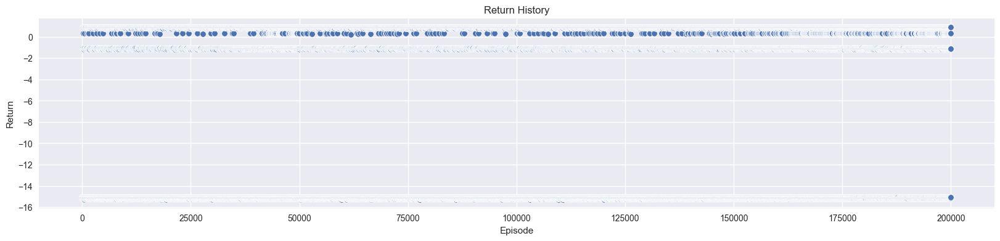

In [63]:
plt.figure(figsize=(20,4))
plt.title("Return History")
sns.scatterplot( [x[0] for x in history_list])
plt.xlabel("Episode")
plt.ylabel("Return")

Text(0, 0.5, 'N Actions')

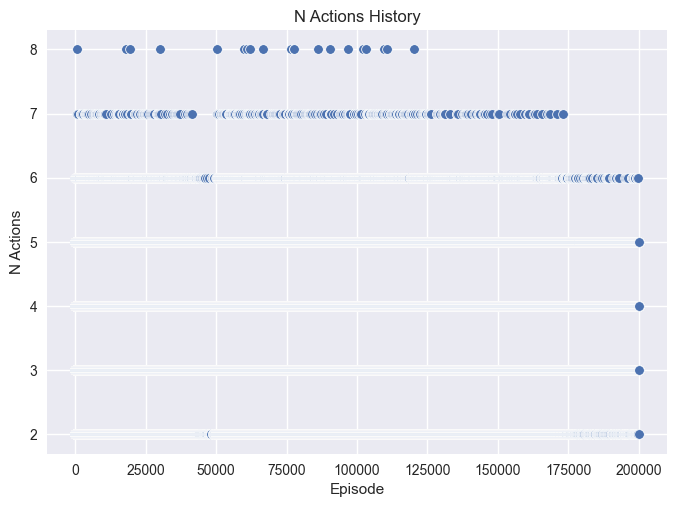

In [64]:
plt.title("N Actions History")
sns.scatterplot( [x[1] for x in history_list])
plt.xlabel("Episode")
plt.ylabel("N Actions")

Text(0, 0.5, 'Epsilon')

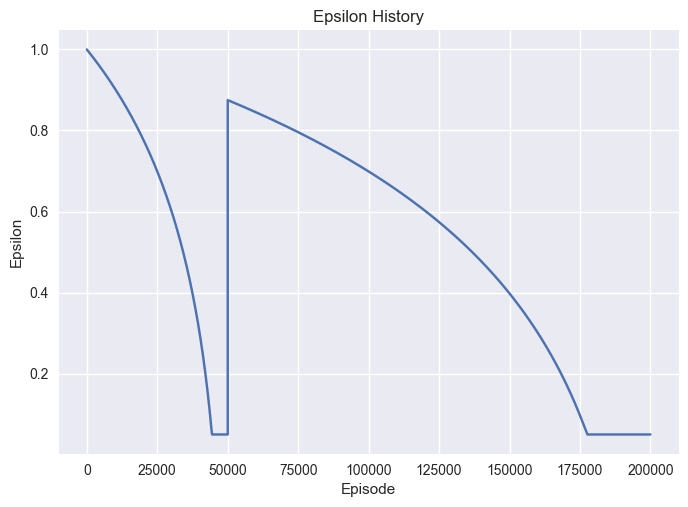

In [65]:
plt.title("Epsilon History")
sns.lineplot( [x[2] for x in history_list])
plt.xlabel("Episode")
plt.ylabel("Epsilon")

# Test agent

In [67]:
for i in range(5):
    try_greedy_policy(f"Agent test no {i}")

Moviepy - Building video video\Agent test no 0.mp4.
Moviepy - Writing video video\Agent test no 0.mp4



Moviepy - Done !
Moviepy - video ready video\Agent test no 0.mp4


Moviepy - Building video video\Agent test no 1.mp4.
Moviepy - Writing video video\Agent test no 1.mp4



Moviepy - Done !
Moviepy - video ready video\Agent test no 1.mp4


Moviepy - Building video video\Agent test no 2.mp4.
Moviepy - Writing video video\Agent test no 2.mp4



Moviepy - Done !
Moviepy - video ready video\Agent test no 2.mp4


Moviepy - Building video video\Agent test no 3.mp4.
Moviepy - Writing video video\Agent test no 3.mp4



Moviepy - Done !
Moviepy - video ready video\Agent test no 3.mp4


Moviepy - Building video video\Agent test no 4.mp4.
Moviepy - Writing video video\Agent test no 4.mp4



Moviepy - Done !
Moviepy - video ready video\Agent test no 4.mp4


# RealTime Game

In [78]:
def play_human_vs_agent():
    s = env.reset()
    d = False

    human_policy = lambda s: int(input(f"Your move (0-{env.getActionsCount()-1}): "))
    greedy_policy = lambda s: q_learning_agent.act(s)
        
    while not d:
        plt.imshow(env.render())
        plt.axis('off')
        plt.show()
        s, d, r= env.two_steps(human_policy, greedy_policy)
    plt.imshow(env.render())
    plt.axis('off')
    plt.show()

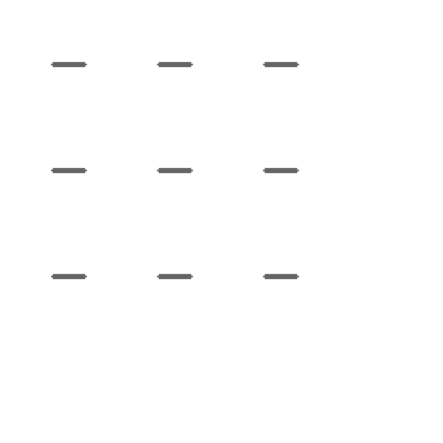

ValueError: invalid literal for int() with base 10: ''

In [80]:
play_human_vs_agent()